# 5. Social-parameter extensions: perception, turning and angular error

## Scientific question

Does fragmentation depend materially on three simplifications of the current social baseline: 360° perception, instantaneous turns and no angular error?

We change **one assumption at a time** before examining an optional combined condition. The purpose is to diagnose sensitivity, not to choose whichever seed produces an attractive animation. No light, gradient cue, global cohesion force or diagnostic feedback is added. All conditions use the existing shared `shiner_model.py`.

**Competing hypotheses.** If fragmentation is insensitive to these extensions, finite local range and initial conditions remain plausible explanations. If matched runs differ substantially, model assumptions contribute to the observed cohesion and the simplified baseline needs that qualification. A difference does not, by itself, establish which formulation is biologically correct.


**Connectivity convention.** All conditions use the same undirected distance graph (separation ≤ 5.5 BL). With restricted perception, this measures potential geometric connectivity; it is not a directed perception or information-flow graph. Omnidirectional close repulsion is retained while the FOV filters orientation and attraction.


In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_one"
PAPERS_DIR = MODEL_DIR

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


from shiner_model import GoldenShinersModel
from checks.check_support import controlled_model
from handlings.trial_one.diagnostics import run_case, summarize_case

OUTPUT_DIR = PAPERS_DIR / "handlings" / "trial_one"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR = OUTPUT_DIR / "data"
FIGURE_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


## Parameters, units and implementation choices

[Puckett et al. (2018)](https://www.nature.com/articles/s41598-018-26037-9) report a 270° field of perception and angular error of 0.01 rad. **Table S1 in their [supplement](https://static-content.springer.com/esm/art%3A10.1038%2Fs41598-018-26037-9/MediaObjects/41598_2018_26037_MOESM1_ESM.pdf), page 15, specifies 1.75 radians per update and 8 updates per second.** Therefore 1.75 rad/update is approximately 100°/update, rather than 100°/second. At the reference `dt=0.125 s`, the corresponding rate in our API is `1.75 / 0.125 = 14 rad/s`.

The extensions use these explicit conventions:

- **FOV:** bearings within ±135° of the current heading affect orientation and attraction. Repulsion remains omnidirectional, following the zone interpretation in [Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065). Exact overlaps are always visible because their bearing is undefined. The visibility boundary is included, with numerical tolerance.
- **Turning:** maximum social-heading change is `max_turn_rate * dt`. Wall reflection is a separate hard boundary response and can change the final heading by more than this social cap.
- **Noise:** a Gaussian angular error is added to the desired heading before the social turn cap. At other timesteps, its standard deviation is `0.01 * sqrt(dt / 0.125)`. This preserves angular-error variance per simulated second; it is an implementation choice beyond the paper's reference timestep.
- **Connectivity:** all comparisons retain the same undirected geometric graph with distance ≤5.5 BL. This measures geometric reachability, not the directed flow of information under a restricted FOV. Changing the diagnostic definition together with FOV would confound the comparison.

The experiments below keep `dt=0.125 s`, speed 1 BL/s, 20 fish, a 20×20 BL reflecting arena, radii 0.5/3.0/5.5 BL, 62.5 s duration and seeds 0–9 fixed. Initial positions and headings are explicitly checked for equality across conditions. Results use the final 12.5 s as a descriptive late window. A fragmented episode lasting at least 2.5 s is called persistent; that duration is a diagnostic convention, not a biological constant.


## Controlled checks before the multi-seed experiment

These checks give the new parameters concrete meanings. Visibility is tested at the front, rear and edge of the viewing sector; the close-range exception is tested separately. Turning is checked away from walls so reflection cannot masquerade as a turn-cap failure. A zero angular-error setting must leave the RNG untouched during decisions, while enabled error must be reproducible under the same seed.


In [2]:
controlled_checks = []

def visible_neighbor(position, **parameters):
    case = controlled_model([(10, 10), position], [(1, 0), (0, 1)], **parameters)
    focal = next(iter(case.agents))
    return len(focal.get_neighbors()) == 1

assert visible_neighbor((11, 10), fov_degrees=270)
assert not visible_neighbor((9, 10), fov_degrees=270)
assert visible_neighbor((9.75, 10), fov_degrees=270)  # Close repulsion is omnidirectional.
assert visible_neighbor((10, 10), fov_degrees=270)   # Overlap has no defined bearing.
for angle, expected in [(134.999, True), (135.0, True), (135.001, False)]:
    radians = np.deg2rad(angle)
    position = (10 + np.cos(radians), 10 + np.sin(radians))
    assert visible_neighbor(position, fov_degrees=270) == expected
controlled_checks.append("FOV front/rear/edge, repulsion exception and exact overlap")

REFERENCE_DT = 0.125
TURN_PER_REFERENCE_UPDATE = 1.75
TURN_RATE = TURN_PER_REFERENCE_UPDATE / REFERENCE_DT
for test_dt in (0.125, 0.0625, 0.03125):
    case = controlled_model(
        [(10, 10), (11, 10)], [(1, 0), (-1, 0)],
        dt=test_dt, max_turn_rate=TURN_RATE,
    )
    focal = next(iter(case.agents))
    old_heading = focal.direction.copy()
    focal.decide()
    angle = np.arctan2(
        old_heading[0] * focal.next_direction[1] - old_heading[1] * focal.next_direction[0],
        np.dot(old_heading, focal.next_direction),
    )
    np.testing.assert_allclose(abs(angle), TURN_RATE * test_dt, atol=1e-12)
    np.testing.assert_array_equal(focal.direction, old_heading)
controlled_checks.append("Social turn cap and rate scaling away from walls")

case = controlled_model([(10, 10)], [(1, 0)], angular_noise=0.0)
numpy_state = copy.deepcopy(case.rng.bit_generator.state)
python_state = case.random.getstate()
case.agents.do("decide")
assert case.rng.bit_generator.state == numpy_state
assert case.random.getstate() == python_state
controlled_checks.append("Zero angular error does not consume randomness")

for test_dt in (0.125, 0.0625, 0.03125):
    case = controlled_model([(10, 10)], [(1, 0)], dt=test_dt, angular_noise=0.01)
    copied_rng = np.random.default_rng()
    copied_rng.bit_generator.state = copy.deepcopy(case.rng.bit_generator.state)
    expected_error = copied_rng.normal(0, 0.01 * np.sqrt(test_dt / REFERENCE_DT))
    focal = next(iter(case.agents))
    focal.decide()
    measured_error = np.arctan2(focal.next_direction[1], focal.next_direction[0])
    np.testing.assert_allclose(measured_error, expected_error, atol=1e-12)
controlled_checks.append("Angular-error standard deviation scales explicitly with dt")

first, _, first_agents = run_case(seed=17, duration=2.5, angular_noise=0.01)
second, _, second_agents = run_case(seed=17, duration=2.5, angular_noise=0.01)
pd.testing.assert_frame_equal(first_agents, second_agents)
controlled_checks.append("Enabled angular error is seed-repeatable")

implicit, _, implicit_agents = run_case(seed=17, duration=2.5)
explicit, _, explicit_agents = run_case(
    seed=17, duration=2.5, fov_degrees=360, max_turn_rate=None, angular_noise=0,
)
pd.testing.assert_frame_equal(implicit_agents, explicit_agents)
controlled_checks.append("Explicit disabled extensions reproduce the default baseline")

pd.DataFrame({"Controlled check": controlled_checks, "Result": "passed"})


,Controlled check,Result
0,"FOV front/rear/edge, repulsion exception and e...",passed
1,Social turn cap and rate scaling away from walls,passed
2,Zero angular error does not consume randomness,passed
3,Angular-error standard deviation scales explic...,passed
4,Enabled angular error is seed-repeatable,passed
5,Explicit disabled extensions reproduce the def...,passed


## A–D: change one assumption at a time

A is the reference. B changes perception only, C changes the social turning limit only, and D adds angular error only. All other model and diagnostic settings remain fixed. We keep each seed's result visible: a condition mean can hide one severe split or several nearly connected 19+1 cases.

The recorded quantities address different questions. Largest-group fraction and connected time measure geometric cohesion; persistent episodes distinguish brief separations from sustained fragmentation; polarization and rotation describe order; MeanNND measures local spacing; distance to the centroid measures global spread.


In [3]:
SEEDS = list(range(10))
DURATION = 62.5
LATE_SECONDS = 12.5
PERSISTENCE_SECONDS = 2.5
CONDITIONS = {
    "A — Baseline": {},
    "B — FOV only": {"fov_degrees": 270.0},
    "C — Turning only": {"max_turn_rate": TURN_RATE},
    "D — Noise only": {"angular_noise": 0.01},
}
initial_states = {}
run_frames = {}
result_rows = []


def run_condition(condition, parameters):
    for seed in SEEDS:
        case, frame, agents = run_case(seed=seed, duration=DURATION, **parameters)
        initial = agents.xs(0, level="Step")
        if seed not in initial_states:
            initial_states[seed] = initial.copy()
        else:
            pd.testing.assert_frame_equal(initial, initial_states[seed])
        assert case.steps == 500
        assert len(frame) == 501
        assert frame["Time"].iloc[-1] == DURATION
        run_frames[(condition, seed)] = frame
        result_rows.append({
            "Condition": condition, "Seed": seed,
            "FOVDegrees": parameters.get("fov_degrees", 360.0),
            "MaxTurnRateRadPerSecond": parameters.get("max_turn_rate", np.nan),
            "AngularNoiseRadAtReferenceUpdate": parameters.get("angular_noise", 0.0),
            "dt": case.dt, "Speed": 1.0, "Fish": len(case.agents),
            **summarize_case(frame, late_seconds=LATE_SECONDS, persistence_s=PERSISTENCE_SECONDS),
        })


for condition, parameters in CONDITIONS.items():
    run_condition(condition, parameters)
    print(f"Completed {condition}: {len(SEEDS)} matched seeds.")

single_factor_results = pd.DataFrame(result_rows)
METRICS = [
    "LateMeanLargestGroupFraction", "PersistentFragmentedTimeFraction",
    "LatePolarization", "LateRotation", "LateMeanNND", "LateMeanDistanceToCentroid",
]
single_factor_summary = single_factor_results.groupby("Condition", sort=False)[METRICS].agg(["mean", "min", "max"])
single_factor_summary.round(4)


Completed A — Baseline: 10 matched seeds.


Completed B — FOV only: 10 matched seeds.


Completed C — Turning only: 10 matched seeds.


Completed D — Noise only: 10 matched seeds.


LateMeanLargestGroupFraction              \
                                         mean    min  max   
Condition                                                   
A — Baseline                           0.9309  0.500  1.0   
B — FOV only                           0.8840  0.615  1.0   
C — Turning only                       0.8850  0.500  1.0   
D — Noise only                         0.9441  0.615  1.0   

                 PersistentFragmentedTimeFraction                \
                                             mean    min    max   
Condition                                                         
A — Baseline                               0.4750  0.000  1.000   
B — FOV only                               0.5864  0.058  1.000   
C — Turning only                           0.5266  0.000  1.000   
D — Noise only                             0.4614  0.000  0.954   

                 LatePolarization                 LateRotation          \
                             mean     min     max         mean     min   
Condition                                                                
A — Baseline               0.8723  0.4564  0.9832       0.1461  0.0070   
B — FOV only               0.7931  0.3227  0.9966       0.2409  0.0111   
C — Turning only           0.8276  0.3276  0.9939       0.2199  0.0174   
D — Noise only             0.8909  0.5926  0.9929       0.1206  0.0078   

                         LateMeanNND                  \
                     max        mean     min     max   
Condition                                              
A — Baseline      0.4704      0.6484  0.5607  1.2687   
B — FOV only      0.9203      0.7127  0.5665  1.3591   
C — Turning only  0.8669      0.5848  0.5404  0.6403   
D — Noise only    0.6006      0.5880  0.5651  0.6034   

                 LateMeanDistanceToCentroid                  
                                       mean     min     max  
Condition                                                    
A — Baseline                         2.2619  1.0871  9.8646  
B — FOV only                         3.1816  1.0697  8.9540  
C — Turning only                     2.9281  1.0724  7.8674  
D — Noise only                       1.7446  1.0849  4.2718

## Paired effects relative to the baseline

For each seed we subtract A from the corresponding B, C or D result. Positive differences mean increases; for fragmentation time, MeanNND and spread, an increase generally signals a different form of deterioration rather than an improvement. No single metric defines success, and a more polarized group can still be fragmented.


In [4]:
baseline = single_factor_results.loc[single_factor_results["Condition"] == "A — Baseline"].set_index("Seed")
paired_effects = []
for condition in list(CONDITIONS)[1:]:
    alternative = single_factor_results.loc[single_factor_results["Condition"] == condition].set_index("Seed")
    difference = alternative[METRICS] - baseline[METRICS]
    paired_effects.append({
        "Condition": condition,
        "Mean change: late largest fraction": difference["LateMeanLargestGroupFraction"].mean(),
        "Seeds with increased late fraction": int((difference["LateMeanLargestGroupFraction"] > 1e-12).sum()),
        "Seeds with decreased late fraction": int((difference["LateMeanLargestGroupFraction"] < -1e-12).sum()),
        "Mean change: persistent fragmentation": difference["PersistentFragmentedTimeFraction"].mean(),
        "Mean change: polarization": difference["LatePolarization"].mean(),
        "Mean change: rotation": difference["LateRotation"].mean(),
        "Mean change: local spacing": difference["LateMeanNND"].mean(),
        "Mean change: global spread": difference["LateMeanDistanceToCentroid"].mean(),
    })
paired_effects = pd.DataFrame(paired_effects)
display(paired_effects.round(4))

interpretation = ["### Actual single-factor results", ""]
for row in paired_effects.to_dict(orient="records"):
    interpretation.append(
        f"- **{row['Condition']}**: mean late largest-group fraction changes by "
        f"{row['Mean change: late largest fraction']:+.3f}; it increases in "
        f"{row['Seeds with increased late fraction']} seeds and decreases in "
        f"{row['Seeds with decreased late fraction']} seeds. Persistent fragmented-time "
        f"fraction changes by {row['Mean change: persistent fragmentation']:+.3f}."
    )
interpretation.append(
    "\nThese are observed paired sensitivities for ten initial configurations. "
    "The following plots show whether mean effects conceal contrasting seeds. "
    "They do not establish biological parameter accuracy or timestep convergence."
)
display(Markdown("\n".join(interpretation)))


,Condition,Mean change: late largest fraction,Seeds with increased late fraction,Seeds with decreased late fraction,Mean change: persistent fragmentation,Mean change: polarization,Mean change: rotation,Mean change: local spacing,Mean change: global spread
0,B — FOV only,-0.0469,2,3,0.1114,-0.0793,0.0948,0.0644,0.9197
1,C — Turning only,-0.0459,1,2,0.0516,-0.0448,0.0738,-0.0636,0.6662
2,D — Noise only,0.0132,2,1,-0.0136,0.0186,-0.0255,-0.0604,-0.5173


### Actual single-factor results

- **B — FOV only**: mean late largest-group fraction changes by -0.047; it increases in 2 seeds and decreases in 3 seeds. Persistent fragmented-time fraction changes by +0.111.
- **C — Turning only**: mean late largest-group fraction changes by -0.046; it increases in 1 seeds and decreases in 2 seeds. Persistent fragmented-time fraction changes by +0.052.
- **D — Noise only**: mean late largest-group fraction changes by +0.013; it increases in 2 seeds and decreases in 1 seeds. Persistent fragmented-time fraction changes by -0.014.

These are observed paired sensitivities for ten initial configurations. The following plots show whether mean effects conceal contrasting seeds. They do not establish biological parameter accuracy or timestep convergence.

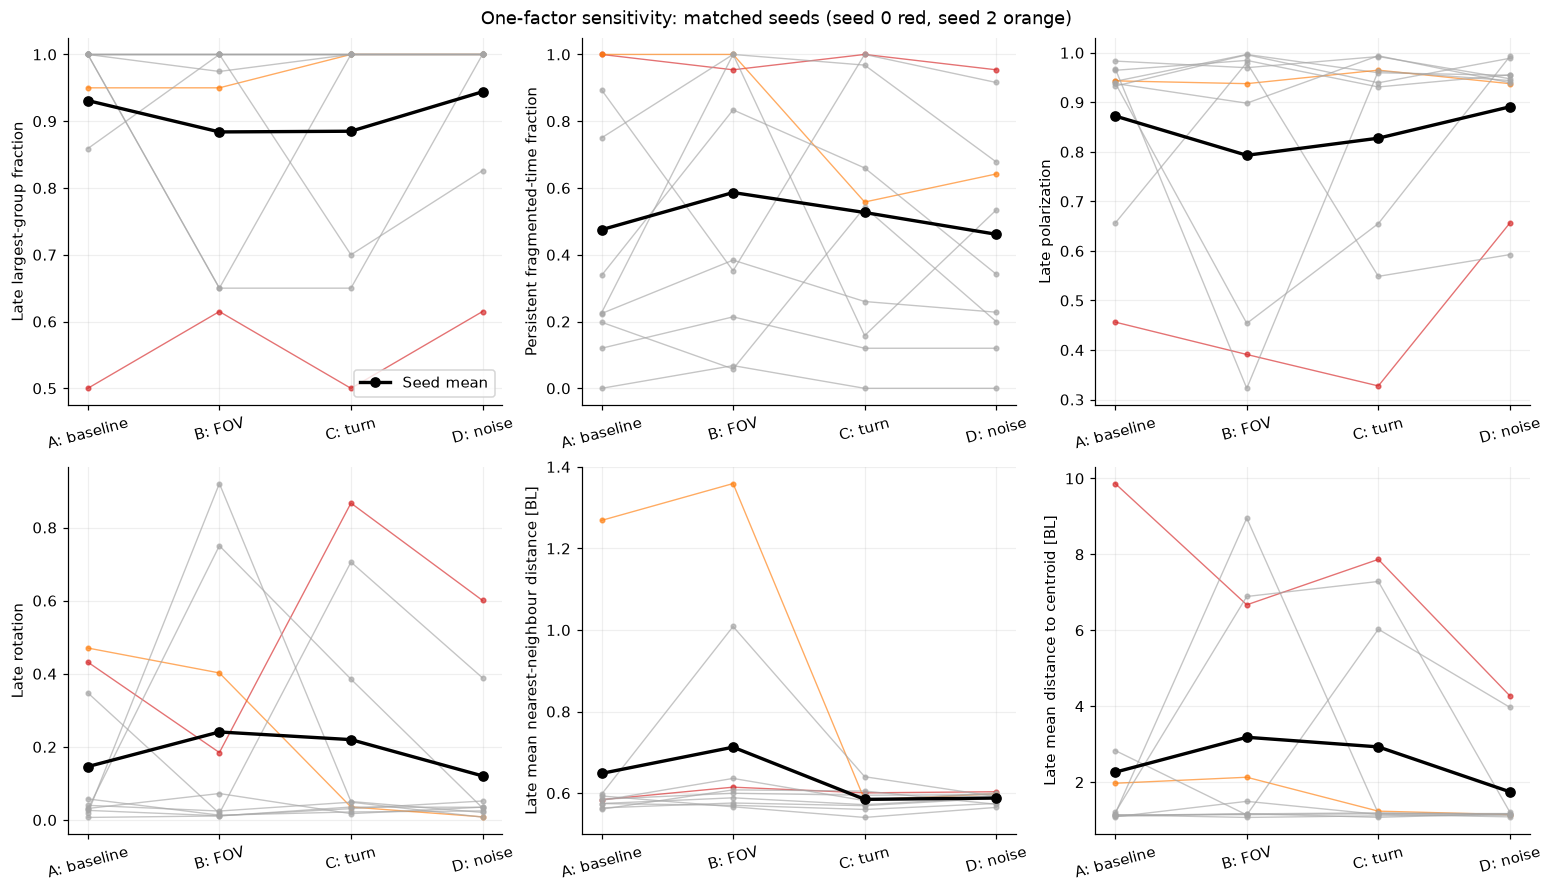

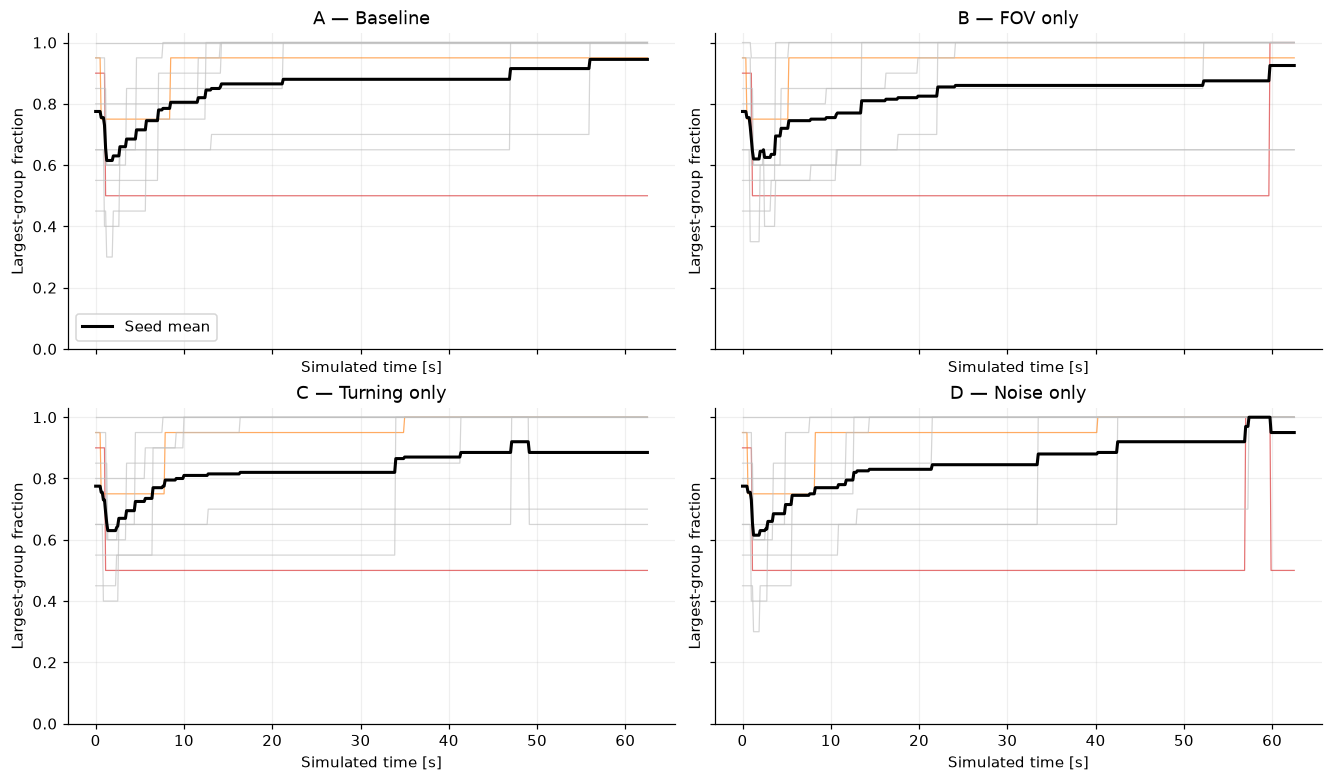

In [5]:
metric_labels = {
    "LateMeanLargestGroupFraction": "Late largest-group fraction",
    "PersistentFragmentedTimeFraction": "Persistent fragmented-time fraction",
    "LatePolarization": "Late polarization",
    "LateRotation": "Late rotation",
    "LateMeanNND": "Late mean nearest-neighbour distance [BL]",
    "LateMeanDistanceToCentroid": "Late mean distance to centroid [BL]",
}
condition_order = list(CONDITIONS)
x = np.arange(len(condition_order))
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for ax, metric in zip(axes.flat, METRICS):
    pivot = single_factor_results.pivot(index="Seed", columns="Condition", values=metric)[condition_order]
    for seed, row in pivot.iterrows():
        color = "tab:red" if seed == 0 else "tab:orange" if seed == 2 else "0.65"
        ax.plot(x, row.to_numpy(), "o-", color=color, alpha=0.65, linewidth=0.9, markersize=3)
    ax.plot(x, pivot.mean().to_numpy(), "ko-", linewidth=2.2, label="Seed mean")
    ax.set_xticks(x, ["A: baseline", "B: FOV", "C: turn", "D: noise"], rotation=15)
    ax.set_ylabel(metric_labels[metric])
    ax.grid(alpha=0.2)
axes.flat[0].legend()
fig.suptitle("One-factor sensitivity: matched seeds (seed 0 red, seed 2 orange)")
fig.savefig(FIGURE_DIR / "05_single_factor_paired_metrics.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True, constrained_layout=True)
for ax, condition in zip(axes.flat, condition_order):
    frames = [run_frames[(condition, seed)] for seed in SEEDS]
    for seed, frame in zip(SEEDS, frames):
        color = "tab:red" if seed == 0 else "tab:orange" if seed == 2 else "0.75"
        ax.plot(frame["Time"], frame["LargestGroupFraction"], color=color, alpha=0.65, linewidth=0.8)
    values = np.stack([frame["LargestGroupFraction"].to_numpy() for frame in frames])
    ax.plot(frames[0]["Time"], values.mean(axis=0), color="black", linewidth=2, label="Seed mean")
    ax.set_title(condition)
    ax.set_xlabel("Simulated time [s]")
    ax.set_ylabel("Largest-group fraction")
    ax.set_ylim(0, 1.03)
    ax.grid(alpha=0.2)
axes.flat[0].legend()
fig.savefig(FIGURE_DIR / "05_single_factor_connectivity.png", dpi=160)
plt.show()


## E: a combined sensitivity probe after the individual comparisons

Only after inspecting A–D do we evaluate E, combining FOV, turning limit and angular error. This condition asks whether the assumptions interact; it is not selected automatically as a replacement baseline. A combined effect need not equal the sum of the individual effects because social trajectories are nonlinear.

The original baseline remains available with all three optional extensions disabled. The 270° FOV, 1.75 rad/reference-update cap and 0.01 rad error are literature-informed values; our 2D geometry, reflective boundary convention, timestep scaling and persistence threshold remain explicit modelling or diagnostic choices.


In [6]:
COMBINED_CONDITION = "E — Combined"
combined_parameters = {"fov_degrees": 270.0, "max_turn_rate": TURN_RATE, "angular_noise": 0.01}
run_condition(COMBINED_CONDITION, combined_parameters)
print(f"Completed {COMBINED_CONDITION}: {len(SEEDS)} matched seeds.")

social_extension_results = pd.DataFrame(result_rows)
assert len(social_extension_results) == 50
assert social_extension_results.groupby("Condition")["Seed"].nunique().eq(10).all()
social_extension_results.to_csv(DATA_DIR / "social_extensions_summary.csv", index=False)

all_order = [*CONDITIONS, COMBINED_CONDITION]
comparison = social_extension_results.groupby("Condition", sort=False).agg(
    LateLargestFraction=("LateMeanLargestGroupFraction", "mean"),
    LateConnectedFraction=("LateConnectedFraction", "mean"),
    PersistentFragmentedTimeFraction=("PersistentFragmentedTimeFraction", "mean"),
    RunsWithPersistentSplit=("PersistentSplitEvents", lambda x: int((x > 0).sum())),
    FinalConnectedRuns=("FinalGroups", lambda x: int((x == 1).sum())),
    LatePolarization=("LatePolarization", "mean"),
    LateRotation=("LateRotation", "mean"),
    LateMeanNND=("LateMeanNND", "mean"),
    LateMeanDistanceToCentroid=("LateMeanDistanceToCentroid", "mean"),
    MissedRepulsionPasses=("MissedRepulsionPasses", "sum"),
    ExactOverlapPairs=("ExactOverlapPairs", "sum"),
)
comparison.round(4)


Completed E — Combined: 10 matched seeds.


,LateLargestFraction,LateConnectedFraction,PersistentFragmentedTimeFraction,RunsWithPersistentSplit,FinalConnectedRuns,LatePolarization,LateRotation,LateMeanNND,LateMeanDistanceToCentroid,MissedRepulsionPasses,ExactOverlapPairs
Condition,,,,,,,,,,,
A — Baseline,0.9309,0.753,0.4750,0,8,0.8723,0.1461,0.6484,2.2619,8,0
B — FOV only,0.8840,0.606,0.5864,1,7,0.7931,0.2409,0.7127,3.1816,6,0
C — Turning only,0.8850,0.700,0.5266,1,7,0.8276,0.2199,0.5848,2.9281,6,0
D — Noise only,0.9441,0.865,0.4614,1,9,0.8909,0.1206,0.5880,1.7446,6,0
E — Combined,0.8800,0.700,0.5080,2,7,0.8343,0.2291,0.5992,3.3048,5,0


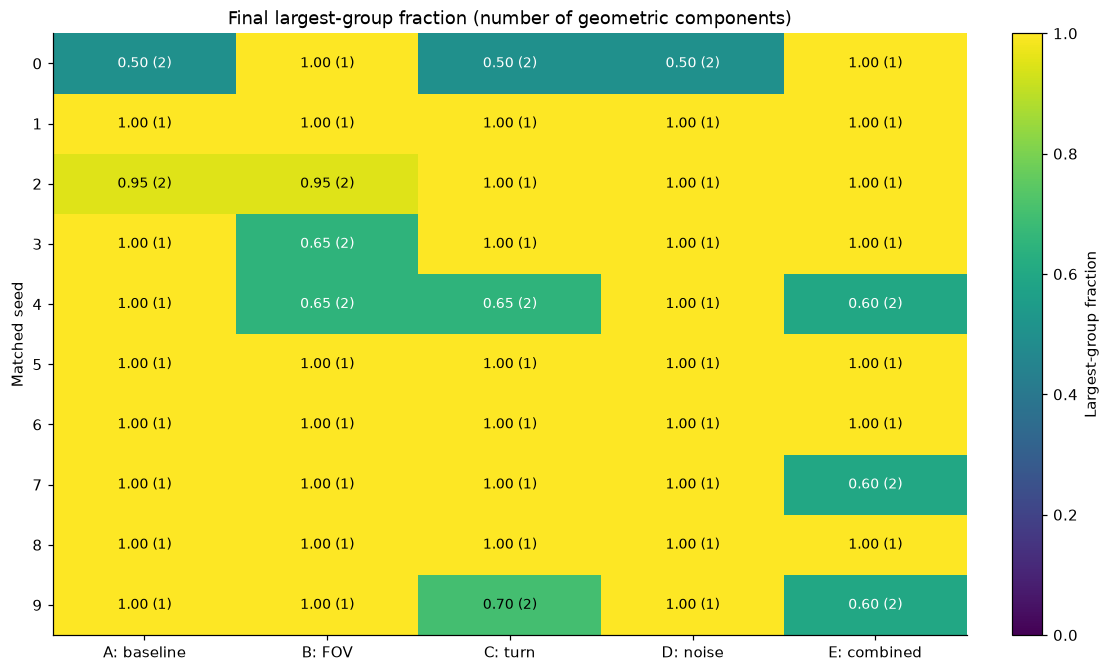

### Interpretation and decision implications

- **A — Baseline**: 8/10 runs end connected; 0/10 have a persistent split from a connected group. Mean late largest-group fraction is 0.931; mean persistent fragmented-time fraction is 0.475.
- **B — FOV only**: 7/10 runs end connected; 1/10 have a persistent split from a connected group. Mean late largest-group fraction is 0.884; mean persistent fragmented-time fraction is 0.586.
- **C — Turning only**: 7/10 runs end connected; 1/10 have a persistent split from a connected group. Mean late largest-group fraction is 0.885; mean persistent fragmented-time fraction is 0.527.
- **D — Noise only**: 9/10 runs end connected; 1/10 have a persistent split from a connected group. Mean late largest-group fraction is 0.944; mean persistent fragmented-time fraction is 0.461.
- **E — Combined**: 7/10 runs end connected; 2/10 have a persistent split from a connected group. Mean late largest-group fraction is 0.880; mean persistent fragmented-time fraction is 0.508.

The geometric, order and spacing measurements must be read together. A low MeanNND can coexist with a disconnected school, and a high polarization can describe parallel subgroups. A final connected snapshot does not exclude earlier fragmentation; conversely a final split can follow a mostly connected run. Persistent split counts exclude runs that were already disconnected until first assembly; persistent fragmented-time fractions can include initial assembly.

This notebook establishes sensitivity to stated social assumptions at speed 1 BL/s and the reference timestep. It does not resolve high-speed integration or wall causality; those require Tests 3–4. The baseline recommendation belongs in Test 6, using all evidence rather than selecting the visually most cohesive condition here. No light has been implemented.

In [7]:
fractions = social_extension_results.pivot(index="Seed", columns="Condition", values="FinalLargestGroupFraction")[all_order]
groups = social_extension_results.pivot(index="Seed", columns="Condition", values="FinalGroups")[all_order]
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
image = ax.imshow(fractions.to_numpy(), vmin=0, vmax=1, cmap="viridis", aspect="auto")
for row in range(len(SEEDS)):
    for column in range(len(all_order)):
        value = fractions.iloc[row, column]
        ax.text(column, row, f"{value:.2f} ({int(groups.iloc[row, column])})", ha="center", va="center",
                color="black" if value > 0.65 else "white", fontsize=9)
ax.set_xticks(np.arange(len(all_order)), ["A: baseline", "B: FOV", "C: turn", "D: noise", "E: combined"])
ax.set_yticks(np.arange(len(SEEDS)), SEEDS)
ax.set_ylabel("Matched seed")
ax.set_title("Final largest-group fraction (number of geometric components)")
fig.colorbar(image, ax=ax, label="Largest-group fraction")
fig.savefig(FIGURE_DIR / "05_final_connectivity_by_condition.png", dpi=160)
plt.show()

notes = ["### Interpretation and decision implications", ""]
for condition, row in comparison.iterrows():
    notes.append(
        f"- **{condition}**: {int(row['FinalConnectedRuns'])}/10 runs end connected; "
        f"{int(row['RunsWithPersistentSplit'])}/10 have a persistent split from a connected group. "
        f"Mean late largest-group fraction is {row['LateLargestFraction']:.3f}; "
        f"mean persistent fragmented-time fraction is {row['PersistentFragmentedTimeFraction']:.3f}."
    )
notes.append(
    "\nThe geometric, order and spacing measurements must be read together. "
    "A low MeanNND can coexist with a disconnected school, and a high polarization "
    "can describe parallel subgroups. A final connected snapshot does not exclude "
    "earlier fragmentation; conversely a final split can follow a mostly connected run. "
    "Persistent split counts exclude runs that were already disconnected until first assembly; "
    "persistent fragmented-time fractions can include initial assembly."
)
notes.append(
    "\nThis notebook establishes sensitivity to stated social assumptions at speed 1 BL/s "
    "and the reference timestep. It does not resolve high-speed integration or wall causality; "
    "those require Tests 3–4. The baseline recommendation belongs in Test 6, using all evidence "
    "rather than selecting the visually most cohesive condition here. No light has been implemented."
)
display(Markdown("\n".join(notes)))
